# CCE 3206 - Digital Signal Processing 
## Practical 3: Frequency response of an FIR filter 
### Name: Dave Galea
### ID: 0283404L

# Task 1 

In [7]:
import numpy as np 

h = np.array([-0.0147, 0.173, 0.342, 0.342, 0.173, -0.0147])
def filter(x):
    # set y to have the same length and type as x 
    y = np.zeros_like(x, dtype = float)

    # iterate overall all input samples
    for n in range(len(x)): # x array is in memory 
        # calculate y_n and store it in y[n]
        y_n = 0
        for k in range(6):
            if (n-k) < 0: # dont try access beyond what x holds
                y_n += 0
            elif (n-k) >= 0:
                y_n += h[k] * x[n-k]

        y[n] = y_n

    return y



# Task 2 

### a) 

In [ ]:
x = np.zeros(10)
x[0] = 1

### b)

In [9]:
y = filter(x)

### c)

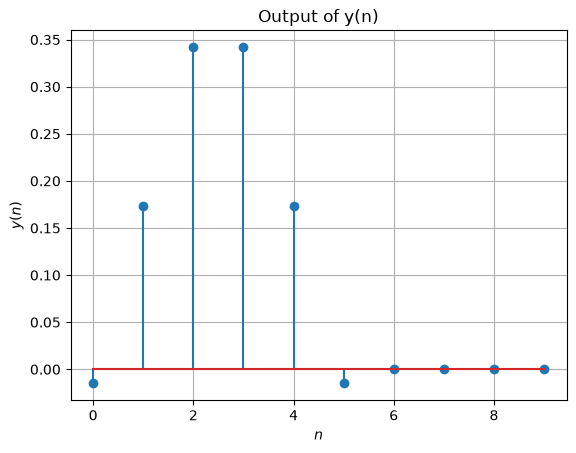

In [87]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
n = np.arange(len(y))
ax.stem(n, y)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.title("Output of y(n)")
plt.show()

# Task 3 


In [13]:
for n in range(len(h)) :
    if y[n] == h[n]:
        print ("h(n) and y(n) match for n = ", n)
    elif y[n] != h[n]:
        print ("h(n) and y(n) do not match for n = ",n)

for n in range(len(h), len(y)):
    if y[n] == 0:
        print("y(n) is zero for n =", n)
    elif y[n] != 0:
        print("y(n) is not zero for n =", n)

h(n) and y(n) match for n =  0
h(n) and y(n) match for n =  1
h(n) and y(n) match for n =  2
h(n) and y(n) match for n =  3
h(n) and y(n) match for n =  4
h(n) and y(n) match for n =  5
y(n) is zero for n = 6
y(n) is zero for n = 7
y(n) is zero for n = 8
y(n) is zero for n = 9


# Task 4 

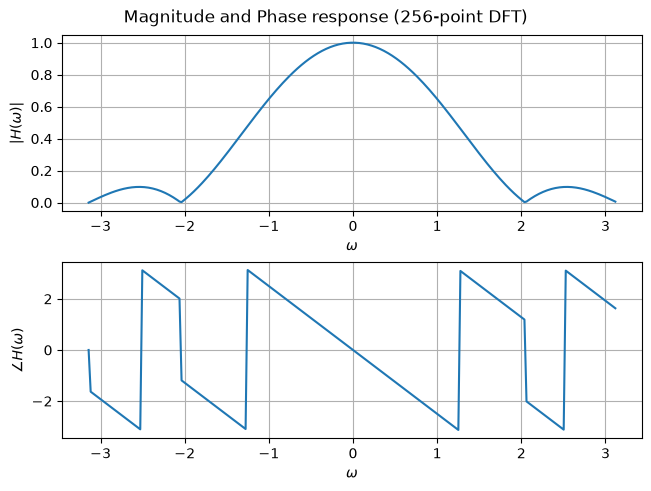

In [86]:
from scipy.fft import fft, fftfreq, fftshift

# use a 256-point DFT
H = fft(h, 256)
# frequencies w corresponding to the output of fft
w = fftfreq(256) * 2 * np.pi
# shift so that w = 0 is at the center
H = fftshift(H)
w = fftshift(w)

fig, ax = plt.subplots(2,1, constrained_layout = True)
fig.suptitle("Magnitude and Phase response (256-point DFT)")

ax[0].plot(w, abs(H)) # -> magnitude reponse 
ax[0].set_xlabel('$\\omega$')
ax[0].set_ylabel('$|H(\\omega)|$')
ax[0].grid(True)

# similarly plot angle of H(w) using np.angle(H)
ax[1].plot(w, np.angle(H)) # -> phase reponse
ax[1].set_xlabel('$\\omega$')
ax[1].set_ylabel('$\\angle H(\\omega)$')
ax[1].grid(True)

plt.show()

# Task 5 

### a)

From the magnitude response graph one can note that higher attenuation happens for higher frequency components, while lower frequency components, around the area $\omega$ = 0, have the least attenuation. The filter is therefore a **low-pass** filter.

### b)

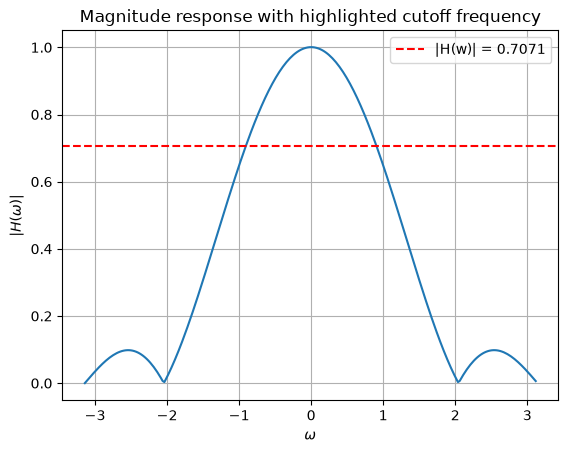

Cutoff frequency is ± 0.9081166264282996 rad/sample


In [94]:
plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0.7071, linestyle='--', color='red',  label = "|H(w)| = 0.7071")
plt.grid(True)
plt.title("Magnitude response with highlighted cutoff frequency")
plt.legend()
plt.show()

# find it with code 
for i in range(len(H)):
    if abs((abs(H[i]) - 0.7071)) < 0.01 and w[i] > 0:
        print(f"Cutoff frequency is \u00B1 {w[i]} rad/sample")

### c)

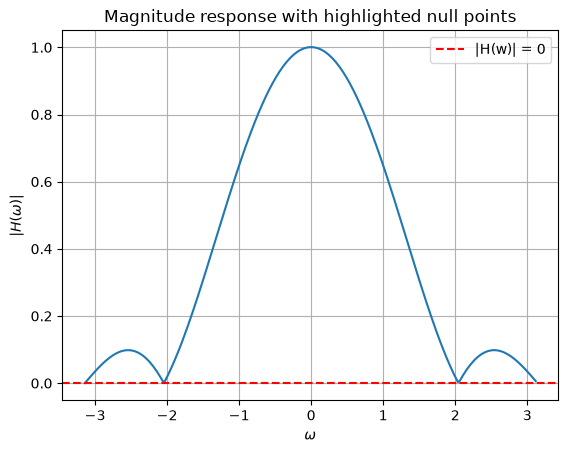

In [93]:
plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0, linestyle='--', color='red', label = "|H(w)| = 0")
plt.grid(True)
plt.title("Magnitude response with highlighted null points")
plt.legend()
plt.show()

# for i in range(len(H)):
#     if abs(H[i]) < 0.01 and w[i] > 0:
#         print(f"Null points are \u00B1 {w[i]} rad/sample")

# issue with the above explained below 


The above code gave the following: 

- Null points are ± 2.0371264863121317 rad/sample
- Null points are ± 2.061670178918302 rad/sample
- Null points are ± 3.117048960983623 rad/sample

Upon further inspection in the graph below it was clear why:

The frequency resolution of the DFT was not high enough to capture all possible frequencies, and therefore, when applying the abs(H[i]) < 0.01 condition, the frequency points both on the ascending and descending ends of the same minimum which descended below that threshold would be counted as null points(this is why the previous code printed 2.037 and 2.062).

To mitigate this, the corrected code compares each magintude with its two respective neighbours, to identify any local minimum. Furthermore, since the positive side of the frequency spectrum does not include $+\pi$, the negative half was considered, allowing the null point $\pm\pi$ to be identified.

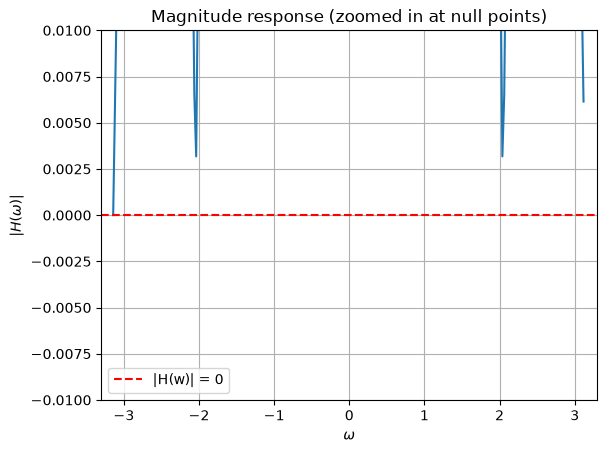

Null points are ± 3.141592653589793 rad/sample
Null points are ± 2.0371264863121317 rad/sample


In [92]:

plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0, linestyle='--', color='red', label = "|H(w)| = 0")
plt.ylim(-0.01, 0.01)
plt.xlim(-3.3, 3.3)
plt.title("Magnitude response (zoomed in at null points)")
plt.grid(True)
plt.legend()
plt.show()

for i in range(len(H)):
    if abs(H[i]) < 0.01 and w[i] <= 0:
        if abs(H[i]) < abs(H[i-1]) and abs(H[i]) < abs(H[(i+1) % len(H)]):
            print(f"Null points are \u00B1 {abs(w[i])} rad/sample")

### d)

# Task 6 

### a)

### b)

### c)

### d)

# Task 7 

# Task 8 

# Task 9 

# Task 10